# 03 · La structure du marché : compétences, réseaux et familles de métiers

L'étape 4 a découpé les textes « compétences attendues » en items. Cette étape s'en sert pour décrire le marché :
1. Quelles compétences sont demandées partout, et lesquelles signent un métier ?
2. Quelles compétences vont ensemble (réseau de cooccurrence) ?
3. Quelles familles de métiers se dessinent quand on les compare par leurs compétences ?
4. Zoom : que demande-t-on aux métiers de la data ?

**Périmètre** : les annonces qui ont un texte de compétences (4,6 % des annonces, surtout à l'État et à l'hôpital), pour
les métiers qui en ont au moins 20. On travaille sur les **formes** des items (texte normalisé, « rigueur »,
« techniques du bâtiment ») plutôt que sur leur rattachement au ROME : à l'échelle d'un item, ce rattachement n'est exact
qu'une fois sur trois (notebook 02). Les formes fréquentes sont propres, mais les variantes d'une même idée ne sont pas
regroupées (« travail en équipe », « travailler en équipe », « savoir travailler en équipe ») : les chiffres par forme
sous-estiment donc les compétences les plus courantes.

Toutes les offres sont comptées en **annonces** (une annonce multi-postes compte une fois).

In [1]:
import os
import warnings

os.environ["TQDM_DISABLE"] = "1"  # pas de barres de progression au chargement du modèle d'embeddings
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import networkx as nx
import numpy as np
import polars as pl
from sklearn.decomposition import NMF

from offres import competences as comp
from offres import donnees, lexique, structure
from offres import familles as fam
from offres import graphiques as g

warnings.filterwarnings("ignore", message="IProgress not found")
g.style()
pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(80)
POURCENT = mtick.FuncFormatter(lambda v, _: f"{v:.0%}".replace("%", " %"))
offres = donnees.offres_service_public()
annonces = offres.unique("annonce_id")
items = pl.read_parquet(donnees.chemin("competences_items.parquet"))
x = structure.items_par_metier(items, offres)
dans_x = annonces.filter(pl.col("annonce_id").is_in(x["annonce_id"].unique().implode()))
print(f"{x['annonce_id'].n_unique():,} annonces, {x['metier'].n_unique()} métiers, {x['forme'].n_unique():,} formes distinctes")
ARMEES = (r"(?i)arm[ée]es?\b|armement|d[ée]fense|interarm[ée]es|marine|renseignement militaire|service national|"
          r"ressources humaines civiles")
print(f"Annonces des services du ministère des Armées : {dans_x.select(pl.col('organisme').str.contains(ARMEES).mean()).item():.0%}")
print("Premiers organismes :")
print(dans_x.group_by("organisme").len().sort("len", descending=True).head(8))
dans_x.group_by("versant").len().with_columns(part=pl.col("len") / pl.col("len").sum()).sort("len", descending=True)

66,238 annonces, 414 métiers, 117,666 formes distinctes
Annonces des services du ministère des Armées : 37%
Premiers organismes :
shape: (8, 2)
┌───────────────────────────────────────────────────────────────────────────────────┬──────┐
│ organisme                                                                         ┆ len  │
│ ---                                                                               ┆ ---  │
│ str                                                                               ┆ u32  │
╞═══════════════════════════════════════════════════════════════════════════════════╪══════╡
│ Service du commissariat des armées (SCA)                                          ┆ 5501 │
│ Armée de terre                                                                    ┆ 2995 │
│ Service infrastructure de la défense (SID)                                        ┆ 2941 │
│ Service de Santé des Armées (SSA)                                                 ┆ 2415 │
│ Nantes Université

versant,len,part
str,u32,f64
"""Fonction Publique de l'Etat""",57948,0.874845
"""Fonction Publique Hospitalière""",8089,0.12212
"""Fonction Publique Territoriale""",193,0.002914
null,8,0.000121


In [2]:
# Libellé lisible de chaque forme : la graphie la plus fréquente, ou une graphie accentuée si elle est assez courante
# (la graphie majoritaire est souvent sans accents : « Organisation et methode »)
graphies = comp.items_des_offres(offres).group_by("forme", "item").len()
ACCENTS = r"[éèêàâùûôîçÉÈ]"
majoritaire = graphies.sort(["len", "item"], descending=[True, False]).group_by("forme", maintain_order=True).first()
avec_accent = (graphies.filter(pl.col("item").str.contains(ACCENTS))
               .sort(["len", "item"], descending=[True, False]).group_by("forme", maintain_order=True).first())
libelles = (majoritaire.join(avec_accent, on="forme", how="left", suffix="_accent")
            .with_columns(libelle=pl.when(pl.col("len_accent") >= 0.2 * pl.col("len")).then("item_accent").otherwise("item")))
LIB = {f: (l.capitalize() if l.isupper() else l[0].upper() + l[1:]) for f, l in libelles.select("forme", "libelle").iter_rows()}
def lib(f, n=60):
    t = LIB.get(f, f)
    return t if len(t) <= n else t[: n - 1] + "…"

## 1. Un socle transversal, puis des compétences de métier

Une forme est dite **transversale** quand plus d'un quart des métiers la citent. Un métier ne « cite » une forme que si
au moins 2 % de ses annonces la mentionnent : sinon, les gros métiers, qui ont des milliers de textes, citeraient tout au
moins une fois, et des compétences de quelques métiers passeraient pour transversales.

31 formes transversales sur 117,666 ; elles pèsent 22% des citations


forme,annonces,metiers,part_metiers
str,u32,u32,f64
"""rigueur""",16431,380,0.917874
"""travail en equipe""",15871,350,0.845411
"""organisation et methode""",13203,212,0.512077
"""autonomie""",11312,371,0.896135
"""utilisation des logiciels de bureautique""",6308,133,0.321256
"""analyse""",6272,230,0.555556
"""utilisation d un systeme d information specifique ou lie a son domaine d activit…",5939,120,0.289855
"""sens des relations humaines""",5642,239,0.577295
"""reactivite""",5398,318,0.768116


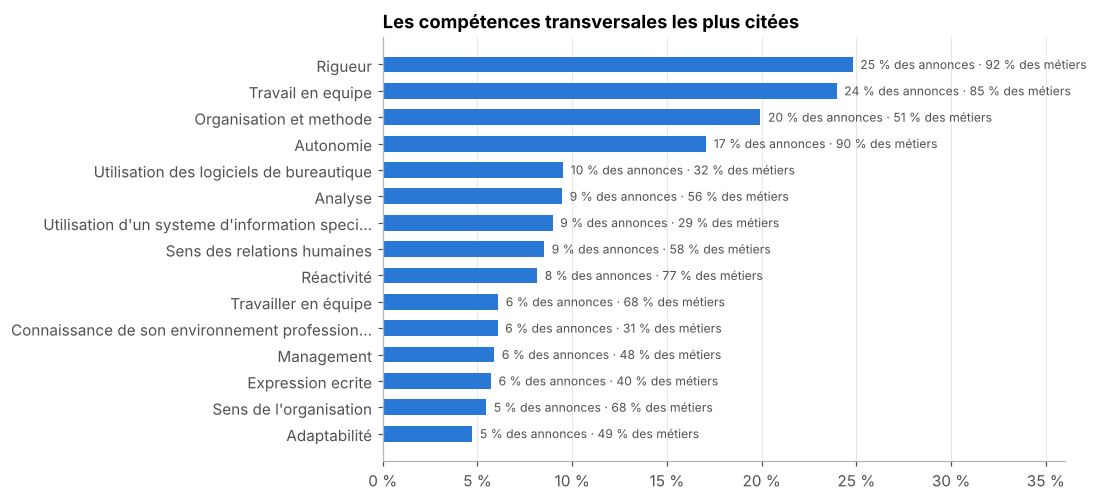

In [3]:
t = structure.transversalite(x)
print(f"{t['transversale'].sum()} formes transversales sur {t.height:,} ; "
      f"elles pèsent {t.filter('transversale')['annonces'].sum() / t['annonces'].sum():.0%} des citations")
top = t.filter("transversale").head(15).reverse()
n_ann = x["annonce_id"].n_unique()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([lib(f, 45) for f in top["forme"]], top["annonces"] / n_ann, color=g.PALETTE[0], height=0.6)
for i, (a, pm) in enumerate(zip(top["annonces"] / n_ann, top["part_metiers"])):
    ax.text(a + 0.004, i, f"{a:.0%} des annonces · {pm:.0%} des métiers".replace("%", " %"), va="center", fontsize=8,
            color="#52514e")
ax.xaxis.set_major_formatter(POURCENT)
ax.set_xlim(0, 0.36)
ax.grid(axis="y", visible=False)
ax.set_title("Les compétences transversales les plus citées")
g.enregistrer(fig, "14_competences_transversales")
t.filter("transversale").select("forme", "annonces", "metiers", "part_metiers")

Le socle est court mais massif : 31 formes, 22 % des citations. Rigueur (92 % des métiers), autonomie (90 %),
travail en équipe (85 %) et réactivité (77 %) sont citées presque partout ; « organisation et méthode », très fréquente
(une annonce sur cinq), ne l'est que par la moitié des métiers. Ces savoir-être viennent sans doute en partie des
référentiels de compétences des ministères, repris tels quels dans les offres de l'État. « Conduite d'un projet » passe
tout juste le seuil (27 % des métiers) : beaucoup de métiers la citent, mais elle est bien plus fréquente dans certains,
comme la data (section 4). Les analyses qui suivent écartent ce socle pour faire ressortir ce qui distingue les métiers.

## 2. Quelles compétences vont ensemble ?

On relie deux compétences de métier quand elles sont citées dans les mêmes annonces plus souvent que le hasard ne le
voudrait. La mesure est l'information mutuelle ponctuelle normalisée (NPMI) : 0 pour deux compétences indépendantes,
1 pour deux compétences toujours citées ensemble. Les 150 compétences non transversales les plus citées sont gardées,
avec les liens de NPMI au moins 0,3 vus dans 20 annonces ou plus, puis le graphe est découpé en communautés (méthode de
Louvain ; le découpage ne change pas, à un nœud près, avec d'autres graines). Pour savoir qui écrit ces compétences, on
regarde aussi l'organisme et le métier des annonces qui citent chaque communauté.

In [4]:
specifiques = t.filter(~pl.col("transversale")).head(150)["forme"].to_list()
paires = structure.cooccurrences(x, specifiques, min_paires=20)
G, groupes = structure.communautes(paires, seuil_npmi=0.3)
freq = dict(zip(t["forme"], t["annonces"]))
print(f"{G.number_of_nodes()} compétences reliées, {G.number_of_edges()} liens, {len(groupes)} communautés")
# Nom de chaque communauté, d'après une forme qui la caractérise
NOMS_COMMUNAUTES = [("circuits administratifs", "Secrétariat, greffe"), ("techniques du batiment", "Bâtiment et prévention"),
                    ("hygiene cybernetique", "SIC et logistique"), ("commande publique", "Finances et achats"),
                    ("regles statutaires", "Gestion du personnel"), ("curiosite intellectuelle", "Savoir-être"),
                    ("conduite du changement", "Encadrement"), ("restauration collective", "Restauration"),
                    ("service national", "Service national, maintenance")]
def nommer(c):
    return next((n for cle, n in NOMS_COMMUNAUTES if any(cle in f for f in c)), lib(max(c, key=freq.get), 30))
noms = [nommer(c) for c in groupes]
organisme = annonces.select("annonce_id", "organisme")
lignes = []
for nom, c in zip(noms, groupes):
    a = x.filter(pl.col("forme").is_in(list(c))).select("annonce_id", "metier").unique("annonce_id").join(organisme, on="annonce_id")
    org = a.group_by("organisme").len().sort(["len", "organisme"], descending=[True, False])
    met = a.group_by("metier").len().sort(["len", "metier"], descending=[True, False])
    lignes.append({"communaute": nom, "competences": len(c), "annonces": a.height,
                   "part_armees": round(a.select(pl.col("organisme").str.contains(ARMEES).mean()).item(), 2),
                   "premier_organisme": f"{org['organisme'][0]} ({org['len'][0] / a.height:.0%})",
                   "premier_metier": met["metier"][0],
                   "competences_principales": " · ".join(lib(f, 40) for f in sorted(c, key=lambda f: -freq[f])[:4])})
communautes = pl.DataFrame(lignes)
communautes

143 compétences reliées, 514 liens, 9 communautés


communaute,competences,annonces,part_armees,premier_organisme,premier_metier,competences_principales
str,i64,i64,f64,str,str,str
"""Secrétariat, greffe""",25,6842,0.01,"""Direction des services judiciaires - CA CHAMBERY (6%)""","""Secrétaire""","""Circuits administratifs · Avoir le sens des relations humaines · Maîtrise des ou…"
"""Bâtiment et prévention""",24,8814,0.84,"""Service infrastructure de la défense (SID) (24%)""","""Chargée / Chargé de travaux et d'exploitation des bâtiments""","""Proactivite et force de proposition · Exploitation et redaction de la documen… ·…"
"""SIC et logistique""",18,4904,0.92,"""Direction Interarmées des Réseaux d'Infrastructure et des Systèmes d'Information…","""Magasinière / Magasinier - Manutentionnaire - Conductrice / Conducteur d'engin d…","""Reglementation dans le domaine de la ge… · Respect des regles elementaires d'hyg…"
"""Finances et achats""",18,7888,0.83,"""Service du commissariat des armées (SCA) (21%)""","""Chargée / Chargé de prestations financières""","""Reglementation et jurisprudence de la c… · Travail en reseau · Indicateurs et ta…"
"""Gestion du personnel""",16,9862,0.78,"""Service du commissariat des armées (SCA) (18%)""","""Chargée / Chargé de gestion administrative et/ou de paie""","""Respect de la confidentialite des infor… · Conception, connaissance et applicati…"
"""Savoir-être""",15,5795,0.06,"""Nantes Université (11%)""","""Assistante / Assistant de direction""","""Rigueur / Fiabilité · Curiosité intellectuelle · Sens des responsabilités · Aisa…"
"""Encadrement""",13,5109,0.54,"""Direction générale de l'armement (DGA) (30%)""","""Architecte système de force, d'arme ou équipement""","""Autonomie initiative · Animation d'équipe · Prise de décision · Méthode"""
"""Restauration""",8,1348,0.99,"""Service du commissariat des armées (SCA) (86%)""","""Chargée / Chargé de restauration, d'intendance""","""Connaissance des bonnes pratiques d'hyg… · Utilisation et entretien des materiel…"
"""Service national, maintenance""",6,1496,0.96,"""Armée de terre (38%)""","""Chargée / Chargé d'accueil, de relation et de service à l'usager""","""Connaissance du service national · Anticipation d'une situation · D'un evenement…"


PosixPath('/home/user/offres-emploi-competences/rapports/figures/15_reseau_competences.png')

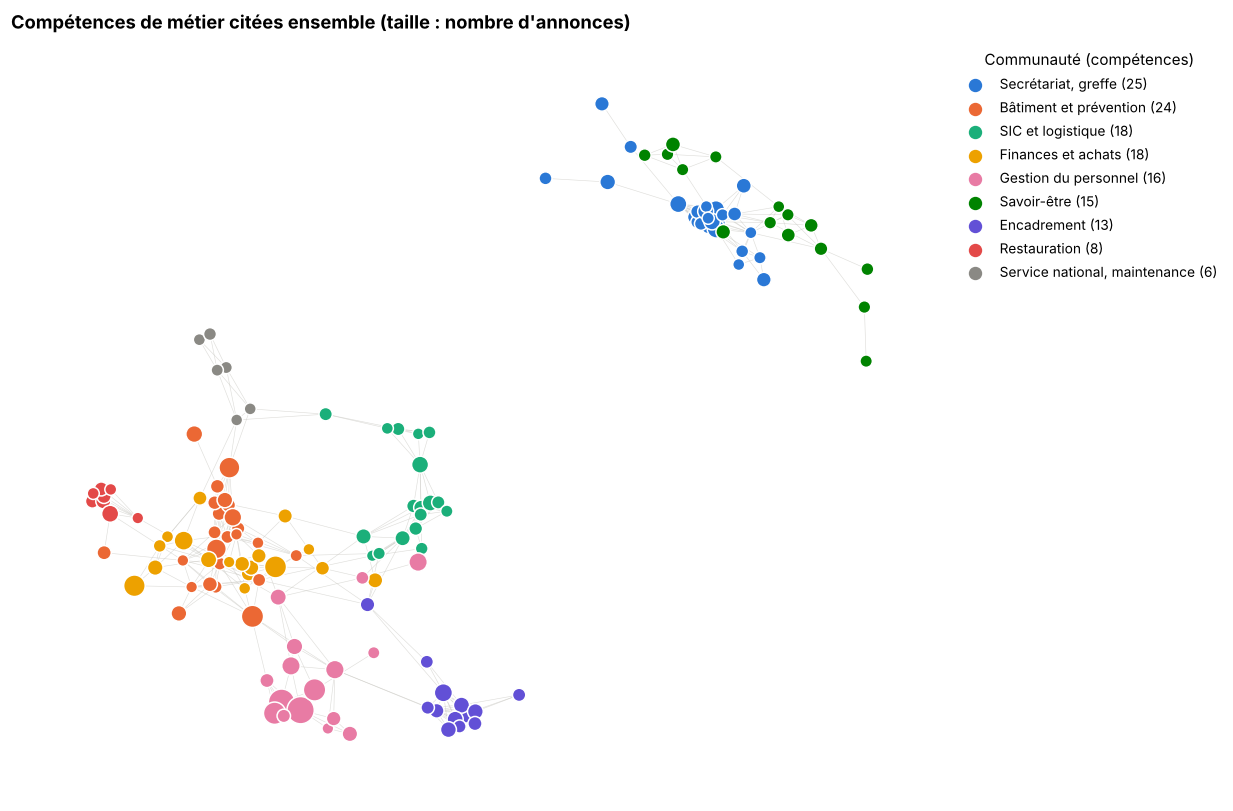

In [5]:
pos = nx.spring_layout(G, weight="weight", seed=3, k=0.35, iterations=200)
COULEURS = g.PALETTE + [g.GRIS, "#2b2a27"]
couleur = {f: COULEURS[i] for i, c in enumerate(groupes) for f in c}
fig, ax = plt.subplots(figsize=(11, 9))
nx.draw_networkx_edges(G, pos, ax=ax, width=0.4, edge_color="#c9c8c2", alpha=0.6)
noeuds = list(G.nodes)
tailles = np.array([freq[f] for f in noeuds])
ax.scatter([pos[f][0] for f in noeuds], [pos[f][1] for f in noeuds], s=20 + 300 * tailles / tailles.max(),
           c=[couleur[f] for f in noeuds], edgecolors="white", linewidths=1, zorder=3)
for i, nom in enumerate(noms):
    ax.scatter([], [], s=60, color=COULEURS[i], label=f"{nom} ({len(groupes[i])})")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False, title="Communauté (compétences)", fontsize=9)
ax.set_axis_off()
ax.set_title("Compétences de métier citées ensemble (taille : nombre d'annonces)")
g.enregistrer(fig, "15_reseau_competences")

Le réseau dit d'abord **qui écrit** les textes de compétences. Plus d'un tiers des annonces du périmètre (37 %)
viennent des services du ministère des Armées, qui puisent dans un même référentiel : sept des neuf communautés sont
écrites à plus de moitié par ces services (bâtiment et prévention, avec le Service d'infrastructure de la défense ; SIC
et logistique, avec la DIRISI ; finances et achats, gestion du personnel et restauration, avec le Service du
commissariat des armées ; encadrement, avec la DGA ; service national). Les deux autres sont d'autres gabarits : le
secrétariat des juridictions (« circuits administratifs », « faire preuve de discrétion ») et des savoir-être
(« curiosité intellectuelle », « aisance relationnelle ») fréquents dans les offres des universités, Nantes Université en
tête. Les communautés recoupent bien des domaines de métier (bâtiment, systèmes d'information, finances, personnel,
restauration), mais elles décrivent autant la façon dont chaque employeur rédige ses annonces que les métiers eux-mêmes.

## 3. Des familles de métiers

Chaque métier est décrit par la part de ses annonces qui citent chaque compétence non transversale (pondérée par
TF-IDF), puis la matrice métiers × compétences est factorisée par NMF : chaque famille est une combinaison de
compétences, et chaque métier est rangé dans la famille où il pèse le plus.

Le nombre de familles est choisi sur la **stabilité** : on refait la factorisation avec six initialisations aléatoires
et on mesure l'accord entre les découpages (indice de Rand ajusté, 1 = identiques). La factorisation retenue part d'une
initialisation déterministe (NNDSVDA) ; le test dit si le découpage tient quand on part d'ailleurs. On retient le plus
grand nombre de familles dont l'accord moyen atteint 0,85 et l'accord minimal 0,75.

Matrice : 414 métiers × 2,421 compétences de métier


K = 9


k,ari_moyen,ari_min
i64,f64,f64
6,0.844378,0.769847
7,0.8735,0.767717
8,0.891816,0.80341
9,0.872687,0.774416
10,0.800886,0.619501
11,0.830002,0.671755
12,0.707862,0.550737
13,0.709141,0.552929
14,0.556272,0.409979


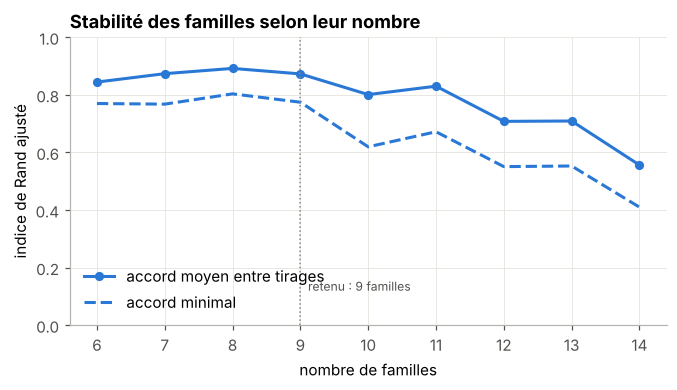

In [6]:
metiers, vocab, m = structure.matrice_metiers(x)
print(f"Matrice : {m.shape[0]} métiers × {m.shape[1]:,} compétences de métier")
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=RuntimeWarning, module="sklearn")  # NMF à initialisation aléatoire
    stab = structure.stabilite(m, list(range(6, 15)), graines=6)
K = int(stab.filter(pl.col("ari_moyen") >= 0.85, pl.col("ari_min") >= 0.75)["k"].max())
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(stab["k"], stab["ari_moyen"], "-o", color=g.PALETTE[0], ms=5, label="accord moyen entre tirages")
ax.plot(stab["k"], stab["ari_min"], "--", color=g.PALETTE[0], label="accord minimal")
ax.axvline(K, color=g.GRIS, lw=1, ls=":")
ax.annotate(f"retenu : {K} familles", (K, 0.12), xytext=(5, 0), textcoords="offset points", fontsize=8, color="#52514e")
ax.set_ylim(0, 1)
ax.set_xlabel("nombre de familles")
ax.set_ylabel("indice de Rand ajusté")
ax.legend(loc="lower left")
ax.set_title("Stabilité des familles selon leur nombre")
g.enregistrer(fig, "16_stabilite_familles")
print(f"K = {K}")
stab

L'accord reste élevé jusqu'à neuf familles (moyen 0,87, minimal 0,77), puis chute dès dix (minimal 0,62). On retient
donc **neuf familles**. L'indice global est dominé par les plus grosses familles ; on mesure donc aussi la robustesse de
**chaque famille** : son meilleur indice de Jaccard avec une famille d'un autre tirage, en moyenne sur six tirages
(1 = mêmes métiers). Le tableau donne aussi, pour les métiers de chaque famille, leur poids médian dans la famille, la
part de leurs citations qui sont transversales et la part qui entre dans le vocabulaire de la factorisation.

In [7]:
W, H = structure.familles(m, K)
etiquette = W.argmax(axis=1)
robustesse = np.zeros(K)
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=RuntimeWarning, module="sklearn")
    for graine in range(6):
        autre = NMF(K, init="random", random_state=graine, max_iter=1000).fit_transform(m).argmax(axis=1)
        for f in range(K):
            a = set(np.where(etiquette == f)[0])
            robustesse[f] += max(len(a & set(np.where(autre == u)[0])) / len(a | set(np.where(autre == u)[0]))
                                 for u in range(K)) / 6

# Ce que les textes de chaque métier disent : part de leurs citations transversales, part entrant dans le vocabulaire
# de la NMF, et poids du métier dans sa famille (faible : le métier est mal décrit par les familles)
transv = set(t.filter("transversale")["forme"])
profil = (x.filter(pl.col("metier").is_in(metiers)).group_by("metier")
          .agg(transversal=pl.col("forme").is_in(list(transv)).mean(), vocabulaire=pl.col("forme").is_in(vocab).mean()))
P = dict(zip(profil["metier"], profil.select("transversal", "vocabulaire").rows()))
poids = W.max(axis=1)
# La famille dont les métiers pèsent le moins est un reste, pas un domaine
reste = int(np.argmin([np.median(poids[etiquette == f]) for f in range(K)]))
NOMS = [("renseignement", "Renseignement, administration, accueil"), ("culinaires", "Restauration collective"), ("achat", "Achats publics"),
        ("batiment", "Bâtiment, travaux, prévention"), ("hospitaliere", "Soins et santé"),
        ("collections", "Archives, documentation, patrimoine"), ("judiciaire", "Juridique, greffe et cabinet"),
        ("sic", "Systèmes d'information et télécoms"), ("financ", "Finances et contrôle interne"),
        ("ressources humaines", "Ressources humaines")]
nom_famille = {reste: "Reste : métiers sans domaine net"}
for f in range(K):
    if f != reste:
        tete = " | ".join(vocab[j] for j in np.argsort(-H[f])[:6])
        nom_famille[f] = next((n for cle, n in NOMS if cle in tete and n not in nom_famille.values()), f"Famille {f + 1}")

annonces_metier = dict(annonces.group_by("metier").len().drop_nulls("metier").iter_rows())
textes_metier = dict(x.group_by("metier").agg(pl.col("annonce_id").n_unique()).iter_rows())
def mediane(f, k):
    return float(np.median([P[metiers[i]][k] for i in np.where(etiquette == f)[0]]))
tableau = pl.DataFrame({
    "famille": [nom_famille[f] for f in range(K)],
    "metiers": np.bincount(etiquette, minlength=K),
    "annonces_avec_texte": [sum(textes_metier[metiers[i]] for i in np.where(etiquette == f)[0]) for f in range(K)],
    "robustesse": robustesse.round(2),
    "poids_median": [round(float(np.median(poids[etiquette == f])), 2) for f in range(K)],
    "part_transversale": [round(mediane(f, 0), 2) for f in range(K)],
    "part_vocabulaire": [round(mediane(f, 1), 2) for f in range(K)],
    "competences_caracteristiques": [" · ".join(lib(vocab[j], 35) for j in np.argsort(-H[f])[:4]) for f in range(K)],
    "exemples": [" · ".join(metiers[i] for i in np.argsort(-W[:, f])[:3]) for f in range(K)],
}).sort("annonces_avec_texte", descending=True)
tableau

famille,metiers,annonces_avec_texte,robustesse,poids_median,part_transversale,part_vocabulaire,competences_caracteristiques,exemples
str,i64,i64,f64,f64,f64,f64,str,str
"""Reste : métiers sans domaine net""",171,15127,0.83,0.1,0.09,0.27,"""Rigueur / Fiabilité · Capacité d'analyse et de synthèse · Force de proposition ·…","""Chargée / Chargé de la coordination administrative · Chargée / Chargé du pilotag…"
"""Renseignement, administration, accueil""",32,11544,0.64,0.14,0.29,0.52,"""Apprehension de l'organisation du … · Communication en langue anglaise a… · Resp…","""Chargée / Chargé de recherches et renseignement · Conseillère / Conseiller en an…"
"""Bâtiment, travaux, prévention""",56,9999,0.85,0.2,0.26,0.44,"""Exploitation et redaction de la do… · Regles du marche public de travaux · Techn…","""Ingénieur travaux et patrimoine immobilier · Cheffe / Chef de projet immobilier …"
"""Juridique, greffe et cabinet""",33,8362,0.19,0.18,0.18,0.44,"""Maîtrise de l'organisation judicia… · Circuits administratifs · Qualité de rédac…","""Chargée / Chargé de l'appui juridique et méthodologique · Assistante / Assistant…"
"""Achats publics""",29,6467,0.65,0.19,0.25,0.47,"""Reglementation et jurisprudence de… · Negociation de l'achat · Indicateurs et ta…","""Acheteuse / Acheteur travaux, immobilier, énergies · Assistante / Assistant acha…"
"""Soins et santé""",35,5923,0.86,0.13,0.09,0.21,"""Hygiene hospitaliere · Observation des regles de l'ethiqu… · Education therapeut…","""Aide-soignante / Aide-soignant · Masseuse / Masseur kinésithérapeute · Manipulat…"
"""Systèmes d'information et télécoms""",28,5529,0.74,0.36,0.16,0.56,"""Conseil et expertise technique dan… · Respect des regles elementaires d'… · Conn…","""Spécialiste des systèmes de communication opérationnels · Responsable réseaux et…"
"""Restauration collective""",13,2221,0.78,0.41,0.21,0.46,"""Connaissance des bonnes pratiques … · Connaissances des produits aliment… · Util…","""Chargée / Chargé de restauration, d'intendance · Chargée / Chargé de restauratio…"
"""Archives, documentation, patrimoine""",17,1066,0.82,0.36,0.17,0.3,"""Environnement patrimonial · Culturel et historique · Techniques documentaires et…","""Encadrante / Encadrant d'un service d'archives · Archiviste · Responsable archiv…"


Premiers organismes de la famille « reste » :
shape: (5, 2)
┌─────────────────────────────────────────────────────────────┬─────┐
│ organisme                                                   ┆ len │
│ ---                                                         ┆ --- │
│ str                                                         ┆ u32 │
╞═════════════════════════════════════════════════════════════╪═════╡
│ Nantes Université                                           ┆ 923 │
│ Université de Strasbourg                                    ┆ 390 │
│ Direction de l'administration pénitentiaire - DISP BORDEAUX ┆ 338 │
│ Direction de l'administration pénitentiaire - DISP PARIS    ┆ 338 │
│ Université Claude Bernard Lyon 1                            ┆ 327 │
└─────────────────────────────────────────────────────────────┴─────┘


Les 414 métiers classés représentent 76% des 1,580,091 annonces, dont 55% dans la territoriale
Plus gros métiers de chaque famille, toutes annonces confondues :
  Reste : métiers sans domaine net : Enseignante / Enseignant (48,004 annonces, 511 avec texte) · Animatrice / Animateur enfance-jeunesse (29,359 annonces, 21 avec texte)
  Achats publics : Responsable de coordination administrative (10,729 annonces, 1012 avec texte) · Chargée / Chargé du pilotage et de la gestion des ressources budgétaires (7,497 annonces, 561 avec texte)
  Systèmes d'information et télécoms : Technicienne / Technicien support utilisateurs (11,207 annonces, 873 avec texte) · Cheffe / Chef de projet maitrise d'œuvre SI (5,463 annonces, 313 avec texte)
  Soins et santé : Travailleuse sociale / Travailleur social (24,384 annonces, 121 avec texte) · Infirmière / Infirmier (24,355 annonces, 1426 avec texte)
  Renseignement, administration, accueil : Chargée / Chargé de gestion administrative et/ou de paie (84,971 a

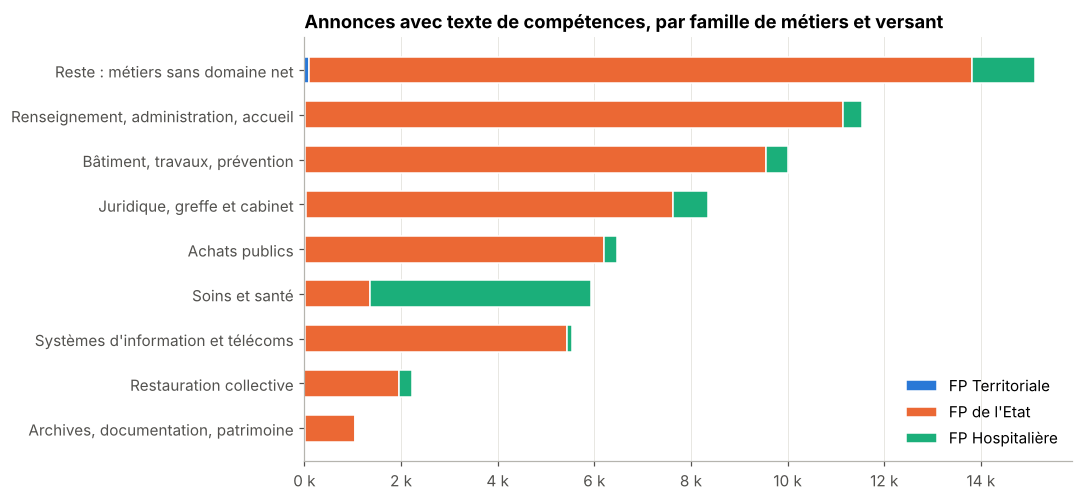

In [8]:
fam_metier = pl.DataFrame({"metier": metiers, "famille": [nom_famille[f] for f in etiquette]})
print("Premiers organismes de la famille « reste » :")
print(x.join(fam_metier, on="metier").filter(pl.col("famille") == nom_famille[reste]).unique("annonce_id")
      .join(organisme, on="annonce_id").group_by("organisme").len().sort("len", descending=True).head(5))
par_versant = (dans_x.join(fam_metier, on="metier").group_by("famille", "versant").len()
               .pivot(on="versant", index="famille", values="len").fill_null(0))
ordre = tableau.sort("annonces_avec_texte")["famille"].to_list()
par_versant = par_versant.with_columns(pl.col("famille").cast(pl.Enum(ordre))).sort("famille")
fig, ax = plt.subplots(figsize=(9, 5))
gauche = np.zeros(par_versant.height)
for versant, couleur in g.VERSANTS.items():
    v = par_versant[versant].to_numpy() if versant in par_versant.columns else np.zeros(par_versant.height)
    ax.barh(par_versant["famille"].cast(pl.Utf8), v, left=gauche, color=couleur, height=0.6,
            label=versant.replace("Fonction Publique", "FP"), edgecolor="white", linewidth=1)
    gauche += v
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v / 1000:.0f} k"))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Annonces avec texte de compétences, par famille de métiers et versant")
g.enregistrer(fig, "17_familles_metiers")
couverture = sum(annonces_metier.get(mm, 0) for mm in metiers) / annonces.height
classees = annonces.filter(pl.col("metier").is_in(metiers))
territoriale = classees.select(pl.col("versant") == "Fonction Publique Territoriale").to_series().mean()
print(f"Les {len(metiers)} métiers classés représentent {couverture:.0%} des {annonces.height:,} annonces, "
      f"dont {territoriale:.0%} dans la territoriale")
# Un métier est classé d'après ses seules annonces avec texte, qui peuvent ne pas lui ressembler ailleurs
print("Plus gros métiers de chaque famille, toutes annonces confondues :")
for f in range(K):
    gros = sorted((metiers[i] for i in np.where(etiquette == f)[0]), key=lambda mm: -annonces_metier.get(mm, 0))[:2]
    print(f"  {nom_famille[f]} : " + " · ".join(f"{mm} ({annonces_metier.get(mm, 0):,} annonces, {textes_metier[mm]} avec texte)" for mm in gros))

Huit familles correspondent à un domaine : soins et santé, bâtiment et prévention, archives et patrimoine, restauration
collective, systèmes d'information, achats publics, renseignement et administration, juridique et greffe. Leur
robustesse varie : de 0,74 à 0,86 pour les cinq premières, 0,64 et 0,65 pour le renseignement et les achats, et
seulement 0,19 pour le juridique, dont les métiers se répartissent autrement d'un tirage à l'autre : c'est la famille la
moins sûre. Deux familles sont des domaines au sens large. « Renseignement, administration, accueil » réunit les
analystes du renseignement et les gestionnaires administratifs et agents d'accueil, dont les annonces (des Armées pour
beaucoup) partagent confidentialité, protection du secret et anglais. La famille juridique, autour du secrétariat des
juridictions, accueille aussi des métiers qui n'ont rien de juridique (agents d'entretien des locaux, agents techniques
polyvalents), signe de plus de sa fragilité.

La plus grande (171 métiers sur 414) n'est pas un domaine mais un **reste** : ses métiers pèsent peu dans toutes les
familles (poids médian 0,10, le plus faible), la factorisation ne trouve pas de combinaison de compétences qui les
décrive. Leurs textes sont souvent des gabarits d'employeurs plutôt que de métiers : universités (Nantes, Strasbourg,
Lyon 1) et administration pénitentiaire en tête.

Les familles sont apprises sur des textes à 87 % de l'État et 12 % de l'hôpital, et chaque métier est classé d'après ses
seules annonces avec texte. On ne les étend donc pas à toutes les offres : 55 % des annonces des métiers classés sont
territoriales, et un gros métier peut être rangé sur la foi de quelques annonces (l'agent des interventions techniques
polyvalent en milieu rural tombe ainsi dans la famille juridique). La figure ne compte que les annonces avec texte.

### Peut-on classer tous les métiers par leur seul intitulé ?

Les familles ne couvrent que les métiers qui ont des textes. Pour les autres, on pourrait ranger chaque métier dans la
famille de ses voisins les plus proches par l'intitulé (embeddings e5). Test en validation croisée sur les métiers déjà
classés :

In [9]:
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold

from offres.embeddings import Modele

E = Modele("e5").encoder([comp.sans_double_genre(mm, True).lower() for mm in metiers])
def voisins(a, ya, b, k=5):
    s = b @ a.T
    proches = np.argsort(-s, axis=1)[:, :k]
    return np.array([np.bincount(ya[p], weights=s[i, p], minlength=K).argmax() for i, p in enumerate(proches)])
prevu = np.zeros(len(metiers), int)
for app, test in StratifiedKFold(5, shuffle=True, random_state=0).split(E, etiquette):
    prevu[test] = voisins(E[app], etiquette[app], E[test])
domaine = etiquette != reste
print(f"Bonne famille retrouvée par l'intitulé : {(prevu == etiquette).mean():.0%} "
      f"(toujours répondre la plus grande famille : {np.bincount(etiquette).max() / len(etiquette):.0%})")
print(f"Exactitude équilibrée (moyenne des familles) : {balanced_accuracy_score(etiquette, prevu):.0%} "
      f"(hasard : {1 / K:.0%})")
print(f"Métiers des familles à domaine net : {(prevu[domaine] == etiquette[domaine]).mean():.0%} bien classés, "
      f"{(prevu[domaine] == reste).mean():.0%} envoyés dans le reste")

Bonne famille retrouvée par l'intitulé : 53% (toujours répondre la plus grande famille : 41%)
Exactitude équilibrée (moyenne des familles) : 46% (hasard : 11%)
Métiers des familles à domaine net : 43% bien classés, 40% envoyés dans le reste


L'intitulé porte un signal réel (exactitude équilibrée de 46 %, contre 11 % au hasard), mais trop faible pour classer un
métier : la bonne famille n'est retrouvée qu'une fois sur deux, et 40 % des métiers des familles à domaine net seraient
envoyés dans le reste. On ne prête donc pas de famille aux métiers sans texte.

## 4. Zoom : les métiers de la data

Le notebook 01 a montré une niche (0,7 % des offres), de cadres, très ouverte au télétravail. Que leur demande-t-on ?

11,239 annonces data, dont 776 avec un texte de compétences
Famille des métiers data classés : [('Reste : métiers sans domaine net', 9), ("Systèmes d'information et télécoms", 2), ('Archives, documentation, patrimoine', 1)]


forme,d,part_data,part_tous,lift
str,u32,f64,f64,f64
"""proposition de solutions optimisees par le biais de methodes scientifiques""",35,0.045103,0.00084,53.662571
"""statistiques exploitation de donnees""",76,0.097938,0.00213,45.975629
"""science des donnees""",33,0.042526,0.001101,38.612843
"""architectures et techniques big data""",56,0.072165,0.001971,36.616813
"""informatique decisionnelle""",39,0.050258,0.001724,29.143994
"""conception d un modele de donnees conformement aux standards""",47,0.060567,0.002232,27.13992
"""identification des donnees du systeme d information conformement aux standards""",41,0.052835,0.002348,22.506101
"""developpement d un systeme informatique""",29,0.037371,0.004101,9.112614
"""creativite""",37,0.04768,0.009695,4.91821


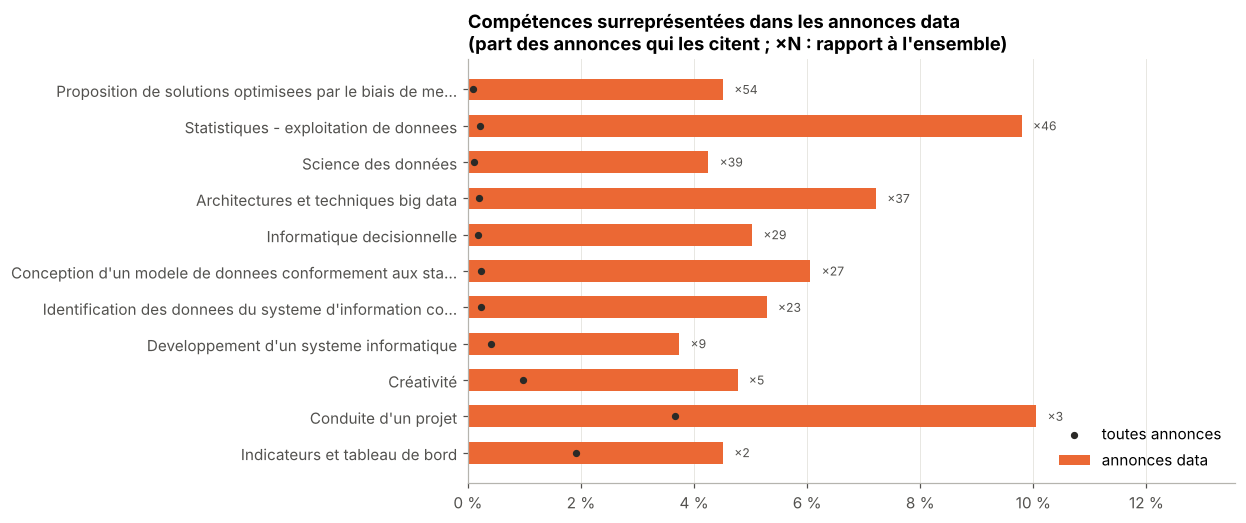

In [10]:
data = annonces.filter(fam.est_data())
ann_data = set(data["annonce_id"].to_list())
xd = items.unique(["annonce_id", "forme"]).with_columns(data=pl.col("annonce_id").is_in(list(ann_data)))
n_d = xd.filter("data")["annonce_id"].n_unique()
n_tot = xd["annonce_id"].n_unique()
print(f"{data.height:,} annonces data, dont {n_d} avec un texte de compétences")
print("Famille des métiers data classés :",
      fam_metier.filter(fam.est_data()).group_by("famille").len().sort(["len", "famille"], descending=[True, False]).rows())
part = (xd.group_by("forme").agg(d=pl.col("annonce_id").filter(pl.col("data")).n_unique(), n=pl.col("annonce_id").n_unique())
        .with_columns(part_data=pl.col("d") / n_d, part_tous=pl.col("n") / n_tot)
        .with_columns(lift=pl.col("part_data") / pl.col("part_tous"))
        .filter(pl.col("d") >= 25, pl.col("lift") >= 2).sort("lift", descending=True))
top_d = part.head(12).reverse()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([lib(f, 55) for f in top_d["forme"]], top_d["part_data"], color=g.PALETTE[1], height=0.6, label="annonces data")
ax.scatter(top_d["part_tous"], range(top_d.height), color="#2b2a27", s=14, zorder=3, label="toutes annonces")
for i, (p, l) in enumerate(zip(top_d["part_data"], top_d["lift"])):
    ax.text(p + 0.002, i, f"×{l:.0f}", va="center", fontsize=8, color="#52514e")
ax.xaxis.set_major_formatter(POURCENT)
ax.set_xlim(0, top_d["part_data"].max() * 1.35)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Compétences surreprésentées dans les annonces data\n(part des annonces qui les citent ; ×N : rapport à l'ensemble)")
g.enregistrer(fig, "18_competences_data")
part.select("forme", "d", "part_data", "part_tous", "lift")

In [11]:
# Termes du lexique dans les annonces data qui ont un texte de compétences. L'intitulé n'est pas lu (« Statisticien »
# y ferait compter la statistique), et le lexique mêle outils, domaines et langues : on les sépare.
DOMAINES = {"Statistiques", "Big data", "Intelligence artificielle", "Machine learning", "Deep learning", "NLP",
            "Computer vision", "Cybersécurité", "Réseaux", "Data visualisation", "ETL / ELT", "Data warehouse"}
def nature(nom):
    return "langue" if lexique.categorie(nom) == "Langue" else "domaine, méthode" if nom in DOMAINES else "outil"
textes = (data.filter(pl.col("competences_texte").is_not_null())
          .with_columns(termes=pl.concat_str([pl.col("competences_texte"), pl.col("specialisation").fill_null("")], separator=" ")
                        .map_elements(lexique.extraire, return_dtype=pl.List(pl.Utf8))))
cites = (textes.explode("termes").drop_nulls("termes")
         .with_columns(nature=pl.col("termes").map_elements(nature, return_dtype=pl.Utf8)))
au_moins = cites.group_by("nature").agg(pl.col("annonce_id").n_unique()).sort("nature")
print(f"{textes.height} annonces data avec un texte ; part citant au moins un terme de chaque nature :",
      {n: f"{a / textes.height:.0%}" for n, a in au_moins.iter_rows()})
(cites.group_by("termes", "nature").agg(annonces=pl.col("annonce_id").n_unique())
 .with_columns(part=pl.col("annonces") / textes.height).sort(["annonces", "termes"], descending=[True, False]).head(15))

808 annonces data avec un texte ; part citant au moins un terme de chaque nature : {'domaine, méthode': '29%', 'langue': '14%', 'outil': '36%'}


termes,nature,annonces,part
str,str,u32,f64
"""Statistiques""","""domaine, méthode""",141,0.174505
"""Python""","""outil""",113,0.139851
"""Anglais""","""langue""",110,0.136139
"""Excel""","""outil""",67,0.082921
"""Big data""","""domaine, méthode""",62,0.076733
"""R""","""outil""",59,0.07302
"""Bureautique (générique)""","""outil""",54,0.066832
"""Linux""","""outil""",48,0.059406
"""Pack Office""","""outil""",48,0.059406


Les annonces data ont un vocabulaire très distinctif : méthodes scientifiques, statistique et exploitation de données,
science des données, big data, informatique décisionnelle, modélisation de données, chacune 20 à 50 fois plus fréquente
que dans l'ensemble des annonces. Pourtant, 9 des 12 métiers data classés tombent dans le reste : ce sont de petits
métiers (moins de 800 annonces avec texte, sur 66 000), trop peu nombreux pour que neuf familles leur en réservent une.

Parmi les 808 annonces data qui ont un texte, 36 % nomment au moins un outil. Python vient en tête (14 %), devant Excel
(8 %), R (7 %), SQL et Linux (6 % chacun) ; la statistique (17 %) et l'anglais (14 %) sont aussi très cités. Les outils
restent minoritaires dans ces textes, qui décrivent surtout des domaines et des méthodes. Le reste du marché (France
Travail, si l'accès arrive) dira si le privé demande les mêmes.

## À retenir

- Un **socle transversal** de 31 formes pèse 22 % des citations : rigueur, autonomie, travail en équipe et réactivité
  sont demandées dans plus des trois quarts des métiers.
- Le **réseau** des compétences de métier montre surtout des **gabarits de rédaction** : sept communautés sur neuf
  viennent majoritairement du ministère des Armées, qui écrit 37 % des textes.
- Une NMF sur les profils de compétences donne **neuf familles**, le plus grand nombre qui reste stable : huit domaines,
  de robustesse inégale (de 0,19 pour le juridique à 0,86 pour les soins), et un reste de 171 métiers mal décrits.
- L'**intitulé seul** ne suffit pas à ranger un métier dans sa famille (une fois sur deux) : on ne généralise ni aux
  métiers sans texte ni aux offres territoriales.
- Les métiers de la **data** ont un vocabulaire très distinctif (statistique, science des données, décisionnel) ; un
  tiers de leurs textes nomment un outil, Python en tête.